In [7]:
from GenPaths import *
from lmfit import Model, Parameters
import lmfit

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec


from PDEhelpers.OpticsDataLoader import *
import PDEhelpers.MathEquations as ME
from PDEhelpers.PhotonInfo import * # this calls DataLoader when defining init
from PDEhelpers.PNJunction import *
import PDEhelpers.PDEStyle as MS

# MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like

rad2deg = 180/np.pi

In [8]:
file_path = PROPATH+"../veraData/HPK_IR_PDE-Feb12_2024-Harry.csv"
df = pd.read_csv(file_path, header=0)

# print(df)
# print(df.info())
print(df.tail())
print("--------------------------")

print(df['Overvoltage'].value_counts())
print(df['Angle'].value_counts())

angles = df['Angle'].unique()
voltages = df['Overvoltage'].unique()


      Wavelength  Angle  Overvoltage  Responsivity       PDE  PDE_error
2188     799.979     60            6  3.429750e-14  0.041089   0.004239
2189     809.978     60            6  3.299900e-14  0.039534   0.003863
2190     820.008     60            6  3.095340e-14  0.037083   0.003730
2191     830.012     60            6  2.754830e-14  0.033003   0.003196
2192     830.012     60            6  2.754830e-14  0.033003   0.003196
--------------------------
Overvoltage
0    260
1    255
2    255
3    255
4    255
5    255
6    254
7    204
8    200
Name: count, dtype: int64
Angle
0     459
15    459
30    459
45    459
60    357
Name: count, dtype: int64


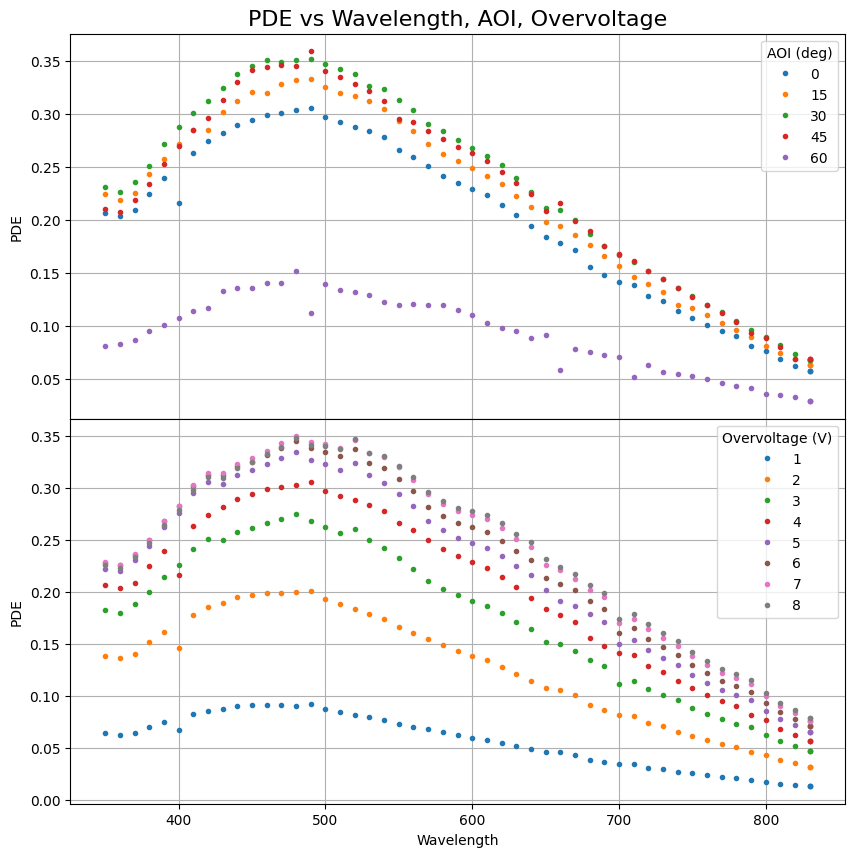

In [9]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize = (10, 10))

# xv4 = df[df['Overvoltage'] == 4]
for angle in angles:
    dt1 = df[(df['Angle'] == angle) & (df['Overvoltage'] == 4)]

    dt1.plot(x='Wavelength', y = "PDE", label = f"{angle:0.0f}", linestyle = "", marker = ".", ax = ax1)
    
ax1.legend(title = "AOI (deg)")
ax1.set_ylabel("PDE")

for voltage in voltages[1:]:
    dt2 = df[(df['Angle'] == 0) & (df['Overvoltage'] == voltage)]
    dt2.plot(x='Wavelength', y = "PDE", label = f"{voltage:0.0f}", linestyle = "", marker = ".", ax = ax2)

ax2.legend(title = "Overvoltage (V)")
ax2.set_ylabel("PDE")

ax1.grid(), ax2.grid()
ax1.set_title("PDE vs Wavelength, AOI, Overvoltage", fontsize = 16)
plt.subplots_adjust(hspace=0)
plt.show()

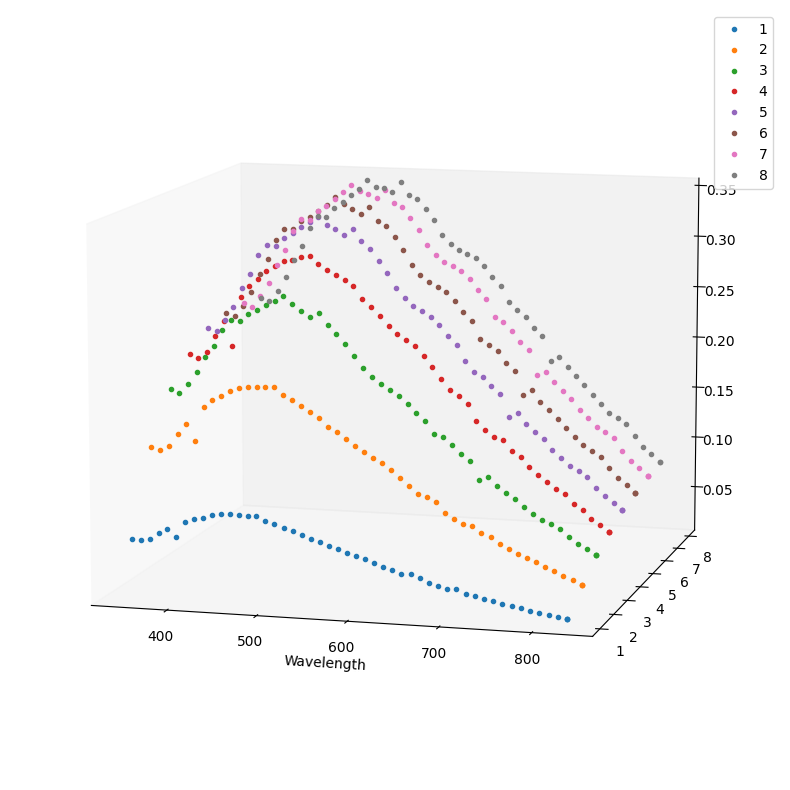

In [66]:
# fig, ax1 = plt.subplots(figsize = (10, 10), projection = ["3d"])
fig = plt.figure(figsize=(10, 10))
ax1 = fig.add_subplot(projection="3d")

for voltage in voltages[1:]:
    dt2 = df[(df['Angle'] == 0) & (df['Overvoltage'] == voltage)]
    dt2.plot(x='Wavelength', y = "PDE", zs = voltage, zdir="y", label = f"{voltage:0.0f}", linestyle = "", marker = ".", ax = ax1)
    

ax1.view_init(10, -75)

In [10]:
## global function we can hopefully control with the objects

def PDE_allArgs(wlen, theta1, FF, tOxide, dp_star, Xpn, dw_star, pe, ph, smoothSigma=None, quantum = False):
    
    photon = PhotonInfo(wlen, theta1)    
    Ttotal = photon.Wave_TotalTransmission(tOxide)
    pn = PNJunction(tOxide = tOxide, dp_star = dp_star, Xpn = Xpn, dw_star=dw_star, pe = pe, ph = ph)
    Wp, Wn = pn.calcW_both(photon)
    
    if quantum:
        nyield = (1240/wlen)/3.2
        pe = 1-(1-pe)**nyield
    PDE = FF * Ttotal * (Wp*pe + Wn*ph)
    
    if smoothSigma is not None: # expensive but simple/works/robust
        stepPerSigma = 3
        stepSize = smoothSigma / stepPerSigma
        newXVals = np.arange(min(wlen), max(wlen) + stepSize, stepSize)
        fullerPDEVals = PDE_allArgs(newXVals, theta1, FF, tOxide, dp_star, Xpn, dw_star, pe, ph, smoothSigma = None)
        fullerPDEVals = gaussian_filter1d(fullerPDEVals, sigma=smoothSigma)
        pdeInt = interp1d(newXVals, fullerPDEVals, kind='linear', fill_value=0)
        return pdeInt(wlen)
    return PDE

def Simple_Transmission(wlen, theta1, tOxide):
    photon = PhotonInfo(wlen, theta1)    
    Ttotal = photon.Wave_TotalTransmission(tOxide)
    return Ttotal

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


(10000,)


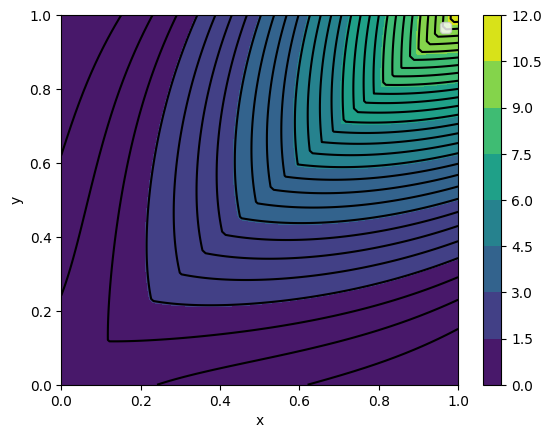

In [47]:
def testFunction(x, y, a, b, c, d = None):
    if d is None:
        return a * x + b * y + c
    else:
        return a * x + b * y + c * d

def testF2d(x, y, a, b):
    
    # return x * y * a + b
    return b*(1-np.abs(y-x)) * (1 + a*x*y)

def testDat_2d(data, a, b):
    
    x = data[:, 0]
    y = data[:, 1]
    
    return testF2d(x, y, a, b)


# Generate some sample data
np.random.seed(0)
x = np.linspace(0, 1, 100)
y = np.linspace(0, 1, 100)
# y = np.random.normal(0, 1, 100)
# data = testFunction(x, y, 2, 3, 4, 5) + np.random.normal(0, 0.5, 100)
X, Y = np.meshgrid(x, y)
Z = testF2d(X, Y, 10, 1)

# Create an lmfit Model
model = Model(testFunction)

# # Set initial parameter values
# params = Parameters()
# params.add('a', value=1.0)
# params.add('b', value=1.0)
# params.add('c', value=1.0)
# params.add('d', value=1.0, vary=False)  # Constrain d to a fixed value

# # Perform the fit
# result = model.fit(data, params, x=x, y=y)

# Print the fit results
# print(result.fit_report())
print(Z.flatten().shape)

### Plotting ###
zlines = np.linspace(min(Z.flatten()), max(Z.flatten()), 30)

# fig = plt.figure(facecolor="black", tickcolor="white")
# plt.scatter(x, data, label='Data')
map = plt.contourf(X, Y, Z)
plt.colorbar(map)

clines = plt.contour(X, Y, Z, zlines, colors="black")

# plt.plot(x, result.best_fit, label='Fit')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()


In [ ]:
# import numpy as np

# def testFunction(x, y, a, b, c, d = None):
#     if d is None:
#         return a * x + b * y + c
#     else:
#         return a * x + b * y + c * d


# # Generate some sample data
# np.random.seed(0)
# x = np.linspace(0, 10, 100)
# y = np.random.normal(0, 1, 100)
# data = testFunction(x, y, 2, 3, 4, 5) + np.random.normal(0, 0.5, 100)

# # Create an lmfit Model
# model = Model(testFunction)

# # Set initial parameter values
# params = Parameters()
# params.add('a', value=1.0)
# params.add('b', value=1.0)
# params.add('c', value=1.0)
# params.add('d', value=1.0, vary=False)  # Constrain d to a fixed value

# # Perform the fit
# result = model.fit(data, params, x=x, y=y)

# # Print the fit results
# print(result.fit_report())

# # Plot the data and the fit
# plt.scatter(x, data, label='Data')
# plt.plot(x, result.best_fit, label='Fit')
# plt.xlabel('x')
# plt.ylabel('y')
# plt.legend()
# plt.show()
